# Let's train a transformer!

In this session you train small transformers on the amplitude data, and find out how the settings chosen before training (the *hyperparameters*) change the learning curves.

- **Part 1 (guided, about 20 minutes):** train a baseline model, learn to read its curves, make a model overfit on purpose and look at longer run checkpoints.
- **Part 2 (free):** change one setting at a time, compare with the baseline, and add your result to the [shared spreadsheet](https://docs.google.com/spreadsheets/d/1lmHcAcWWMWpOF6BKaHu1cQ40khnsMDCfJxaUoaLX7wA/edit?usp=sharing).

**On Google Colab:** first choose *File → Save a copy in Drive*, and check that *Runtime → Change runtime type* is set to **T4 GPU**.

## Setup

In [1]:
# On Google Colab only: download the code and the data (skipped on your own laptop)
import os
if not os.path.isfile('../train.py'):
    !git clone https://github.com/f-charton/Transformer-demo /content/Transformer-demo
    %cd /content/Transformer-demo/notebooks

In [2]:
import sys; sys.path.insert(0, "."); sys.path.insert(1, "..") 
import ast
import matplotlib.pyplot as plt
import os
import torch
import glob, gzip, shutil
import train
from IPython.display import display, HTML

# unzip data files (run only once)
if not os.path.isfile('../data/4.train'): 
    for f in sorted(glob.glob('../data/*.gz')):
        print("unzipping", f)
        with gzip.open(f, 'rb') as src, open(f[:-3], 'wb') as dst:
            shutil.copyfileobj(src, dst)

print("NVIDIA GPU:", torch.cuda.is_available(), "| Apple GPU:", torch.backends.mps.is_available())

NVIDIA GPU: False | Apple GPU: True


The next cell defines the functions used in the rest of the notebook: one to train a model, one to read the log file of a run, two to plot the curves, and one to make the row for the spreadsheet.

In [3]:
# support functions

def train_model(my_params):
    """Train a model and return the path of its log file."""
    params = train.get_parser().parse_args([])
    for key, value in my_params.items():
        assert hasattr(params, key), f"Unknown setting: {key}"
        setattr(params, key, value)
    train.check_model_params(params)
    train.main(params)
    return os.path.join(params.dump_path, "train.log")


def read_log(file):
    losses, perf, n_params, minutes = [], [], 0, 0
    with open(file) as f:
        for line in f:
            if "- LOSS" in line:                  # training loss, printed every 200 steps
                losses.append(float(line.split("LOSS:")[1].split()[0]))
            if "__log__:" in line:                # validation results, printed after every epoch
                perf.append(ast.literal_eval(line.split("__log__:")[1]))
                h, m, s = line.split(" - ")[2].split(":")          # time since the start, h:mm:ss
                minutes = int(h) * 60 + int(m) + int(s) / 60
            if "Number of parameters:" in line:
                n_params = int(line.split(":")[-1])
    return losses, perf, n_params, minutes
    

def curve(perf, key):
    """One validation curve, with one value per epoch. Example: curve(perf, 'acc')"""
    return [p.get("valid_AMPLITUDE_" + key, 0) for p in perf]


def plot_runs(runs, names=None):
    """Plot the curves of the runs listed in names (by default, all the runs)."""
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, name in enumerate(names or runs):
        losses, perf, n_params, minutes = read_log(runs[name])
        epochs = range(1, len(perf) + 1)
        x_train = [len(perf) * (j + 1) / len(losses) for j in range(len(losses))]   # spread the training losses over the epochs
        color = f"C{i}"
        ax1.plot(x_train, losses, "--", color=color, linewidth=1)
        ax1.plot(epochs, curve(perf, "xe_loss"), "o-", color=color, markersize=3, label=name)
        ax2.plot(epochs, curve(perf, "acc"), "o-", color=color, markersize=3, label=name)
        ax3.plot(epochs, [100 * v for v in curve(perf, "avg_correct_module")], "o-", color=color, markersize=3, label=name)
        ax3.plot(epochs, [100 * v for v in curve(perf, "avg_correct_sign")], "--", color=color)
    ax1.set_title("Loss (dashed: training, solid: validation)")
    ax1.set_yscale("log")
    ax2.set_title("Validation accuracy (%)")
    ax2.set_ylim(0, 100)
    ax3.set_title("Magnitude (solid) and sign (dashed) correct (%)")
    ax3.set_ylim(0, 100)
    ax3.axhline(50, color="grey", linestyle=":")       # the sign guessed at random
    for ax in (ax1, ax2, ax3):
        ax.set_xlabel("epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.show()


def plot_signs(file):
    """Validation accuracy on the positive and on the negative coefficients."""
    losses, perf, n_params, minutes = read_log(file)
    epochs = range(1, len(perf) + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(epochs, curve(perf, "acc_1"), "o-", markersize=3, label="positive coefficients")
    plt.plot(epochs, curve(perf, "acc_-1"), "o-", markersize=3, label="negative coefficients")
    plt.title("Validation accuracy by sign of the true coefficient (%)")
    plt.xlabel("epoch")
    plt.ylim(0, 100)
    plt.legend()
    plt.show()


def spreadsheet_row(file, changed="", baseline="", new=""):
    """Show the row to copy into the shared results spreadsheet."""
    losses, perf, n_params, minutes = read_log(file)
    if not losses or not perf:
        print("This run has not finished its first epoch: nothing to report yet.")
        return
    row = ["YOUR NAME",                                       # Name (type yours over it)
           changed, baseline, new,                            # Parameter changed, baseline and new value
           "",                                                # Expected effect
           n_params,                                          # Model parameter count
           round(minutes, 1),                                 # Run time (minutes)
           round(losses[-1], 3),                              # Final training loss
           round(curve(perf, "xe_loss")[-1], 3),              # Final validation loss
           round(max(curve(perf, "acc")), 1),                 # Best validation accuracy (%)
           round(curve(perf, "avg_correct_sign")[-1], 2),     # Sign accuracy (fraction, 0 to 1)
           round(curve(perf, "avg_correct_module")[-1], 2)]   # Magnitude accuracy (fraction, 0 to 1)
    # shown as a table: a copied table row pastes into separate spreadsheet columns
    cells = "".join(f"<td style='border:1px solid #999; padding:4px 10px; text-align:left'>{value}</td>" for value in row)
    display(HTML(f"<table style='border-collapse:collapse'><tr>{cells}</tr></table>"))

# Part 1: a guided first run

## 1.1 The data

Each line of the data files is a word made of the letters `a` to `f`, followed by its integer coefficient. The number in the file name is the loop order: `5.train` contains 5-loop words, which have 10 letters.

The model reads the word and must write the coefficient: first its sign, then its magnitude. An answer counts as correct only if both are right.

In [4]:
with open('../data/5.train') as f:
    lines = f.readlines()

print(len(lines), "training examples. \n The first five:")
for line in lines[:5]:
    word, coefficient = line.split()
    print("  ", word, "->", coefficient)

253880 training examples. 
 The first five:
   abbabfafbd -> -16
   afbfbceaee -> -144
   caeaafbaff -> 96
   aeacecbfbf -> 24
   bacddddbbd -> -192


## 1.2 Train the baseline

This is the reference model for the whole session: a small transformer with one encoder layer and one decoder layer. Everything you try in Part 2 will be compared with it.

Training prints a lot of text. The lines to watch are the ones with `LOSS`, printed every 200 training steps, and the validation results at the end of each epoch. The run takes a few minutes.

In [5]:
baseline_params = {
    # data
    'reload_data': 'amplitude:../data/5.train',  # training file (5 loops)
    'eval_data': '../data/5.valid',              # validation file: 5,000 examples never used for training
    'eval_size': -1,                             # validate on the whole validation file
    'batch_size_eval': 1000,
    'max_examples': -1,                          # number of training examples used (-1: the whole file)
    # length of the run
    'epoch_size': 50000,                         # validate every 50,000 training examples (one "epoch")
    'max_epoch': 10,                             # stop after 10 epochs
    # model
    'n_enc_layers': 1,                           # layers in the encoder
    'n_dec_layers': 1,                           # layers in the decoder
    'enc_emb_dim': 128,                          # embedding dimension in the encoder
    'dec_emb_dim': 128,                          # embedding dimension in the decoder
    'n_enc_heads': 8,                            # attention heads in the encoder
    'n_dec_heads': 8,                            # attention heads in the decoder
    'dropout': 0,
    'attention_dropout': 0,
    # optimisation
    'batch_size': 64,                            # training examples per step
    'optimizer': 'adam,lr=0.0001',               # optimizer and learning rate
}

runs = {}                                        # all your runs: name -> log file
runs['baseline'] = train_model(baseline_params)

INFO - 11/18/26 20:20:54 - 0:00:00 - ============ Initialized logger ============
INFO - 11/18/26 20:20:54 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /Users/juliepages/miniconda3/envs/jupyter_env/lib/python3.11/site-packages/ipykernel_launcher.py -f /Users/juliepages/Library/Jupyter/runtime/kernel-610acc7f-7c4a-45d3-b68b-0eccf1779548.json --exp_id 2026_11_18_20_20_54
                                     cpu: False

## 1.3 Read the curves

The three plots share the same horizontal axis, the epoch. Here one epoch is 50,000 training examples, after which the model is tested on the validation file.

- **Left, the loss.** The dashed line is the loss on the training examples, the solid line the loss on the validation file. Lower is better. As long as the two stay together, the model is learning something that holds for words it has never seen.
- **Middle, the accuracy.** The percentage of validation words whose coefficient is entirely correct.
- **Right, magnitude and sign.** The percentage of validation words with the correct magnitude (solid) and with the correct sign (dashed). A model guessing the sign at random gets 50% (dotted line).

Two questions to answer from your plots:

1. Is the model still improving when the run stops?
2. Are the training loss and the validation loss close to each other?

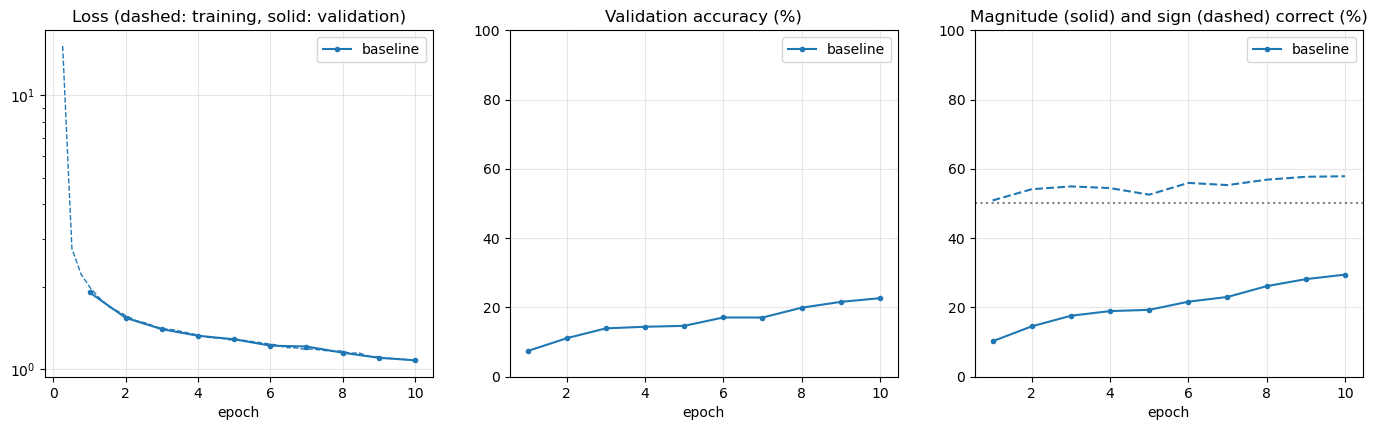

In [6]:
plot_runs(runs, ['baseline'])

**Add your baseline to the [shared spreadsheet](https://docs.google.com/spreadsheets/d/1lmHcAcWWMWpOF6BKaHu1cQ40khnsMDCfJxaUoaLX7wA/edit?usp=sharing).** Run the cell below, copy the row it shows, and paste it into the first empty row. Everyone trains the same baseline, so the spread of these rows across the class tells us how much two identical runs can differ. Keep that spread in mind when you judge whether a change had an effect.

In [7]:
# line to copy into the shared results spreadsheet
spreadsheet_row(runs['baseline'], changed="none (baseline)", baseline="", new="")

YOUR NAME,none (baseline),,,,851712,2.4,1.072,1.079,22.7,0.58,0.29


## 1.4 Overfit on purpose

Train the baseline again with one change: the model only gets 5,000 training examples (2% of the file), which it sees over and over again.

Before you run it: what do you expect the training loss to do? And the validation loss?

In [8]:
my_params = dict(baseline_params)     # a copy of the baseline ...
my_params['max_examples'] = 5000      # ... with one change

runs['5000 examples'] = train_model(my_params)

INFO - 11/18/26 20:23:17 - 0:02:23 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/18/26 20:23:17 - 0:00:00 - ============ Initialized logger ============
INFO - 11/18/26 20:23:17 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /Users/juliepages/miniconda3/envs/jupyter_env/lib/python3.11/site-packages/ipykernel_launcher.py -f /Users/juliepages/Library/Jupyter/runtime/kernel-610acc7f-7c4a-45d3-b68b-0eccf1779548.json 

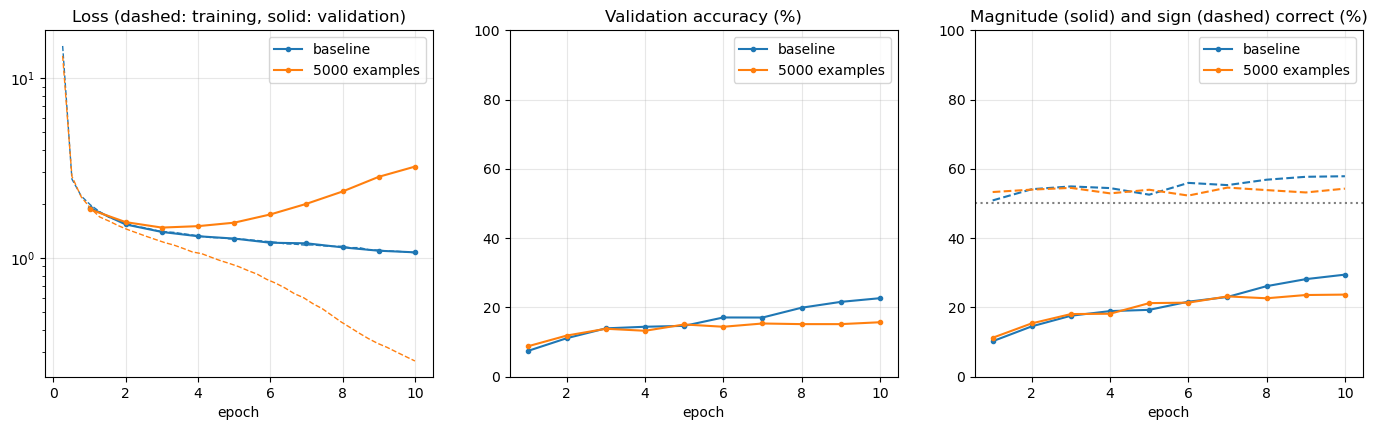

In [9]:
plot_runs(runs, ['baseline', '5000 examples'])

The training loss keeps falling while the validation loss turns around and rises. The model is memorising its 5,000 examples, which does not help with words it has never seen. This is **overfitting**, and the gap between the dashed and the solid line is how you recognise it.

The opposite situation is **underfitting**: both losses stay high, because the model is too small or has not trained enough.

## 1.5 Much longer runs

Your baseline trained for a few minutes. The repository also contains the log of a larger model trained for much longer: 2 + 2 layers, embedding dimension 200, 6-loop data (words of 12 letters), 51 epochs of 300,000 examples, 1 hour 46 minutes of training. The next cell only reads that log; it does not train anything.

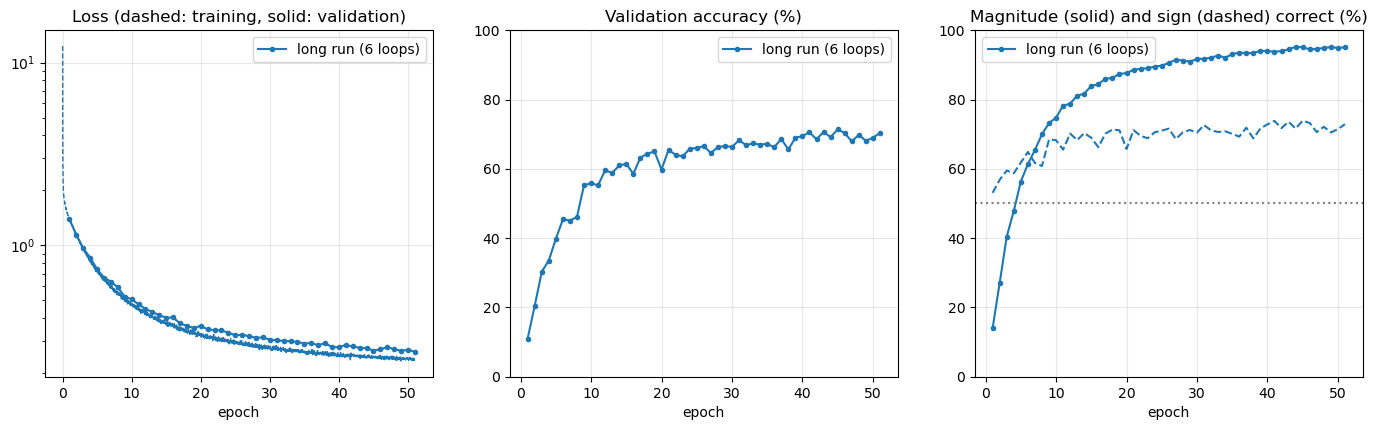

In [10]:
plot_runs({'long run (6 loops)': '../checkpoint/train.log'})

The magnitude and the sign are not learned at the same speed. What does each of them reach at the end of the run?

The next plot splits the validation accuracy according to the sign of the true coefficient. What happens from one epoch to the next?

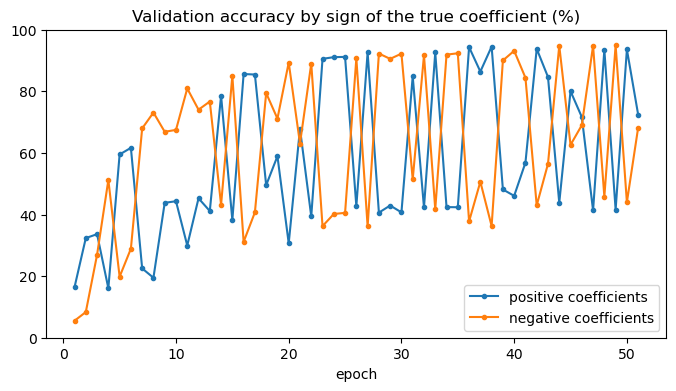

In [11]:
plot_signs('../checkpoint/train.log')

The repository contains a second long run, on the 5-loop data of your baseline: 2 + 2 layers, embedding dimension 256, learning rate 0.0003, 47 epochs of 100,000 examples, about 47 minutes of training.

This time the model goes through four stages. It learns the magnitude, then the curves flatten (a first plateau), then it learns the sign, then the curves flatten again (a second plateau). At which epoch does each stage begin? Which stage had the 6-loop run reached when it stopped?

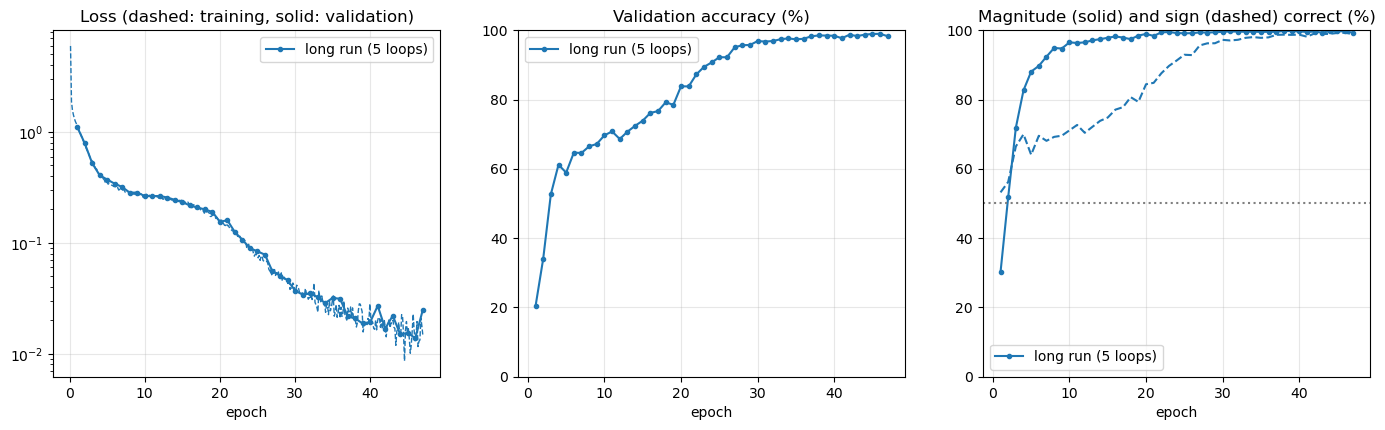

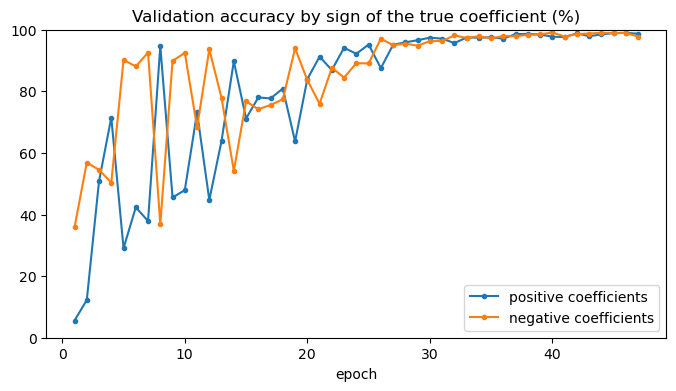

In [12]:
plot_runs({'long run (5 loops)': '../checkpoint_double_plateau/train.log'})
plot_signs('../checkpoint_double_plateau/train.log')

# Part 2: your own experiments

Now explore. The rules:

- **Change one setting at a time**, starting from the baseline, so that every run can be compared with it.
- **Write down what you expect before you run**, in the "Expected effect" column of the [spreadsheet](https://docs.google.com/spreadsheets/d/1lmHcAcWWMWpOF6BKaHu1cQ40khnsMDCfJxaUoaLX7wA/edit?usp=sharing).
- **Add a row for every run**, including the ones where nothing changes or the model fails to learn.

Some interesting things to find: a run that overfits, a run that underfits, a run that does not learn at all, a run where the magnitude is learned well before the sign, and the best accuracy reachable in a few minutes of training.

For each new experiment, edit the cell below (or copy it), then run the two cells that follow it.

In [13]:
my_params = dict(baseline_params)     # start from the baseline ...

# ... and change ONE thing: remove the # in front of one line, and try several values.
# The value in the baseline is given in [brackets].
#
# --- Size of the model ---
# my_params['enc_emb_dim'] = 256; my_params['dec_emb_dim'] = 256   # [128] embedding dimension: 32, 64, 256, 512 (a multiple of the number of heads)
# my_params['n_enc_layers'] = 2; my_params['n_dec_layers'] = 2     # [1] number of layers: 2, 4 (bigger models take longer to train)
# my_params['n_enc_heads'] = 1; my_params['n_dec_heads'] = 1       # [8] attention heads: 1, 2, 4, 16
#
# --- Optimisation ---
# my_params['optimizer'] = 'adam,lr=0.001'                         # [adam,lr=0.0001] learning rate: from 0.00001 to 0.01
# my_params['batch_size'] = 256                                    # [64] batch size: 16, 32, 256, 512 (small batches take longer to train)
my_params['optimizer'] = 'sgd,lr=1'                           # another optimizer: sgd, adamw, rmsprop (each has its own good learning rate)
# my_params['optimizer'] = 'adam_warmup,lr=0.001,warmup_updates=500'   # learning rate increased progressively over the first 500 steps
#
# --- Amount of data, and overfitting ---
# my_params['max_examples'] = 20000                                # [-1 = all 253,880] training examples: 1000, 5000, 20000, 50000
# my_params['dropout'] = 0.1                                       # [0] dropout: 0.1, 0.3, 0.5. Does it help the '5000 examples' run of Part 1?
#
# --- Length of the run ---
# my_params['max_epoch'] = 20                                      # [10] more epochs: the run takes proportionally longer
#
# --- Other architectures and encodings ---
# my_params['model_type'] = 'lstm'                                 # [transformer] recurrent networks: 'lstm', 'gru'
# my_params['architecture'] = 'encoder_only'                       # [encoder_decoder] 'encoder_only', 'decoder_only'
# my_params['base'] = 13# [1000] base in which the coefficient is written: 10, 100
# my_params['enc_pos_emb'] = 'abs_sinusoidal'; my_params['dec_pos_emb'] = 'abs_sinusoidal'   # [abs_learned] positional embeddings

name = 'sgd'                       # a short name for this run, used in the plots (for example 'lr=0.001')

assert my_params != baseline_params, "Change one setting before running this cell"
runs[name] = train_model(my_params)

INFO - 11/18/26 20:26:46 - 0:03:29 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/18/26 20:26:46 - 0:00:00 - ============ Initialized logger ============
INFO - 11/18/26 20:26:46 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /Users/juliepages/miniconda3/envs/jupyter_env/lib/python3.11/site-packages/ipykernel_launcher.py -f /Users/juliepages/Library/Jupyter/runtime/kernel-610acc7f-7c4a-45d3-b68b-0eccf1779548.json 

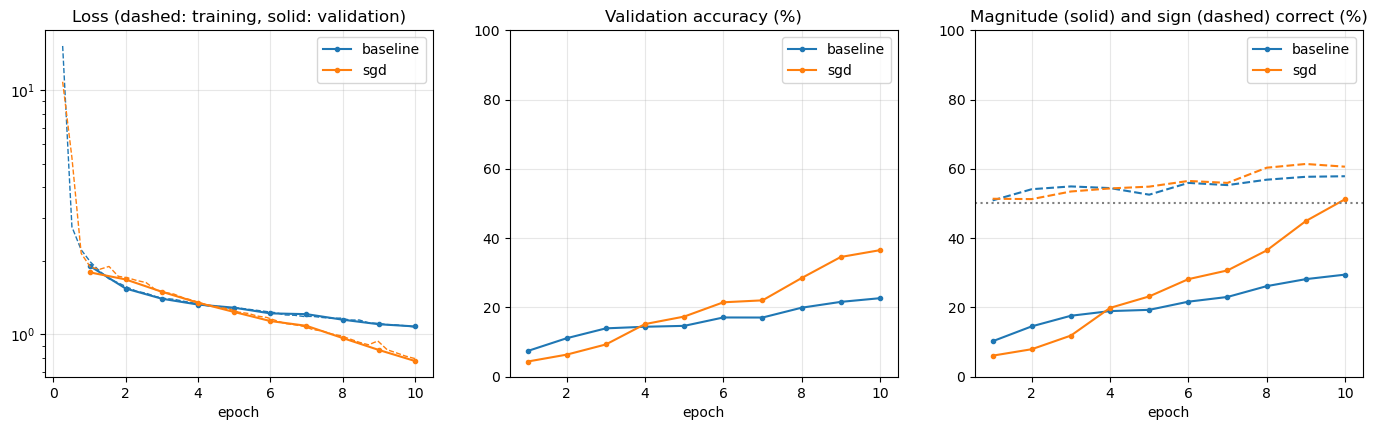

In [14]:
# your run against the baseline
plot_runs(runs, ['baseline', name])

In [15]:
# line to copy into the shared results spreadsheet
# fill in the setting you changed, its value in the baseline and its value in this run
spreadsheet_row(runs[name], changed="", baseline="", new="")

YOUR NAME,,,,,851712,1.9,0.797,0.779,36.5,0.61,0.51


To compare several of your runs, list their names. With no list, all your runs are plotted.

Your runs so far: ['baseline', '5000 examples', 'sgd']


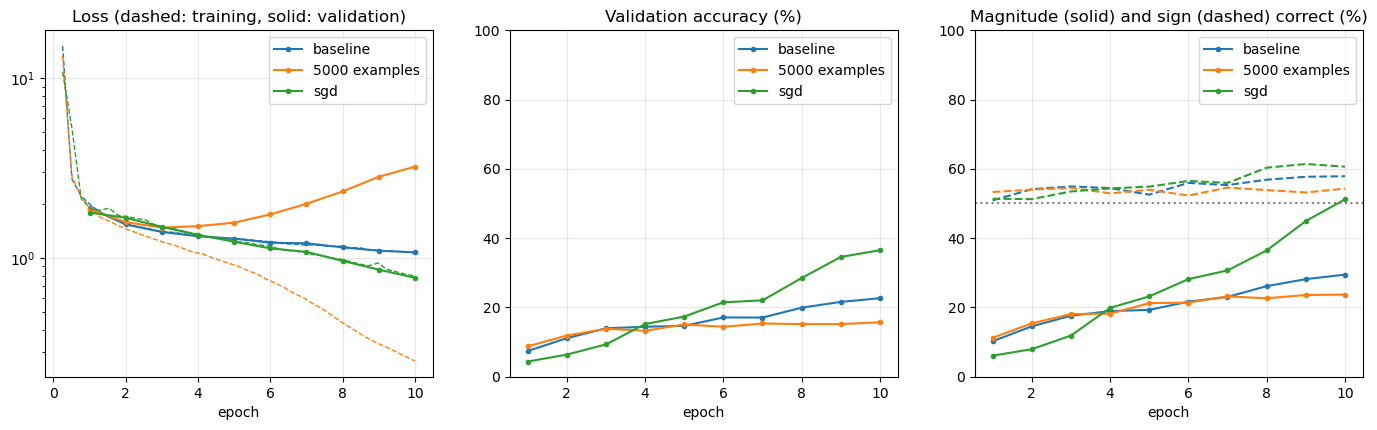

In [16]:
print("Your runs so far:", list(runs))
plot_runs(runs)        # or, for example: plot_runs(runs, ['baseline', 'lr=0.001', 'lr=0.01'])

# Bonus question: a double plateau at 4 loops?

The second long run of section 1.5 goes through two plateaus on the 5-loop data. Can you reproduce this with the 4-loop data (words of 8 letters)?

The 4-loop files are much smaller: 10,208 training examples. There is no `4.valid` file, so the cell below validates on `4.test` (1,000 examples).

INFO - 11/18/26 20:28:39 - 0:01:53 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/18/26 20:28:39 - 0:00:00 - ============ Initialized logger ============
INFO - 11/18/26 20:28:39 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /Users/juliepages/miniconda3/envs/jupyter_env/lib/python3.11/site-packages/ipykernel_launcher.py -f /Users/juliepages/Library/Jupyter/runtime/kernel-610acc7f-7c4a-45d3-b68b-0eccf1779548.json 

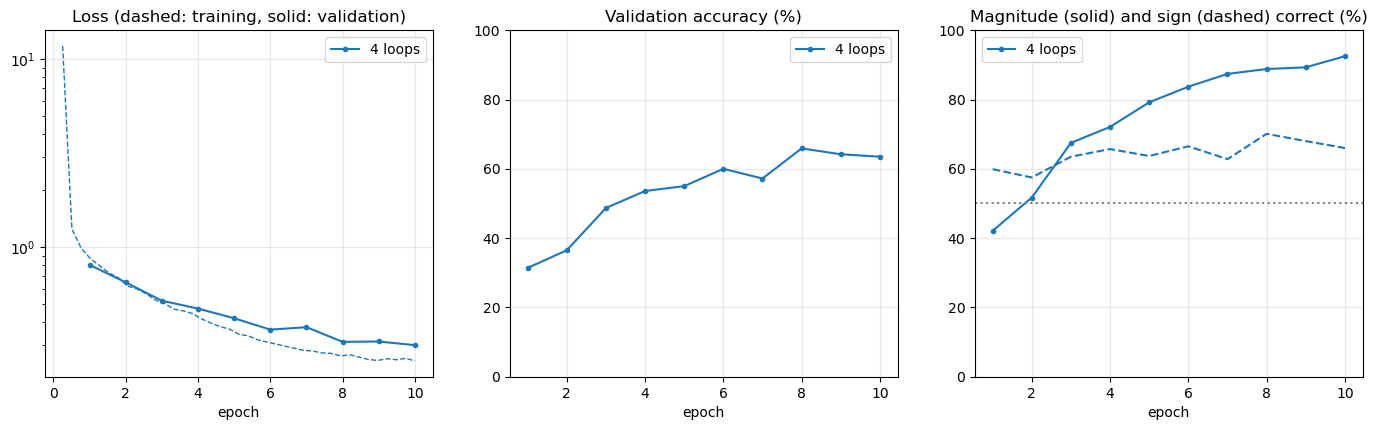

In [17]:
my_params = dict(baseline_params)                        # start from the baseline ...
my_params['reload_data'] = 'amplitude:../data/4.train'   # ... with the 4-loop training file
my_params['eval_data'] = '../data/4.test'                # ... and the 4-loop test file for the validation

# change what you think is needed to see the two plateaus (model size, learning rate, length of the run, ...)

runs['4 loops'] = train_model(my_params)
plot_runs(runs, ['4 loops'])